# Fine-tuning and resuming

The notebook uses a CUDA GPU when available and falls back to CPU otherwise.

Fine-tuning begins with existing network parameters and preserves the encoder,
head shapes, preprocessing and class taxonomy. This offline example creates a
small model to demonstrate freezing, unfreezing and training-state resumption. **Its weights are random, not pretrained.**

To load a pretrained network for your own run, start with a local checkpoint:

```python
from pathlib import Path

import torch
from cellseg_models_pytorch.models.cellpose import CellPose

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = Path("checkpoints/cellpose.safetensors")
model = CellPose.from_pretrained(checkpoint_path, device=device).model
```

Use that checkpoint's class labels, preprocessing and architecture when training
and reloading. The steps below use the small demonstration model; the training page
explains how to prepare real data.


## Setup


In [1]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from skimage.color import label2rgb

from cellseg_models_pytorch.models.cellpose.cellpose_unet import cellpose_nuclei
from cellseg_models_pytorch.transforms.functional.cellpose import gen_flow_maps

# Fix the seed so the small demonstration can be repeated.
torch.manual_seed(0)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")

Device: cuda


## Prepare the example data


In [2]:
# Give each example object its own instance label.
rows, cols = np.mgrid[:64, :64]
instances = np.zeros((64, 64), dtype=np.int32)
instances[(rows - 24) ** 2 + (cols - 24) ** 2 < 8**2] = 1
instances[(rows - 44) ** 2 + (cols - 44) ** 2 < 6**2] = 2

# Repeated RGB channels and samples keep this demonstration small.
image = np.repeat((instances > 0)[..., None], 3, axis=2).astype(np.float32)
images = torch.from_numpy(image.transpose(2, 0, 1)).unsqueeze(0).repeat(2, 1, 1, 1)

# Both objects share a class, even though their instance labels differ.
class_targets = (
    torch.from_numpy((instances > 0).astype(np.int64)).unsqueeze(0).repeat(2, 1, 1)
)

# Flows point toward each object's centre and are a separate training target.
flow_array = gen_flow_maps(instances).astype(np.float32)
flow_targets = torch.from_numpy(flow_array).unsqueeze(0).repeat(2, 1, 1, 1)

## Create the network and freeze its encoder


In [3]:
model = cellpose_nuclei(2, enc_name="resnet18", enc_pretrain=False).to(device)

encoder = model[model.enc_name]
for parameter in encoder.parameters():
    parameter.requires_grad_(False)

# Only train parameters that are still unfrozen.
optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=1e-4
)

Freezing parameters alone does not freeze BatchNorm statistics. Keep the frozen
encoder in evaluation mode after putting the rest of the network into training mode.


In [4]:
# Enable training; the frozen encoder stays in evaluation mode.
model.train()
encoder.eval()

optimizer.zero_grad(set_to_none=True)
prediction = model(images.to(device))["nuc"]

# Learn the class labels and the flows together.
classification_loss = F.cross_entropy(prediction.type_map, class_targets.to(device))
flow_loss = F.mse_loss(prediction.aux_map, flow_targets.to(device))
loss = classification_loss + flow_loss

# Backpropagation computes gradients; the optimizer updates the weights.
loss.backward()
optimizer.step()

print("Training loss:", float(loss.detach()))

Training loss: 3.764005661010742


Unfreeze for a lower-learning-rate phase. Rebuilding the optimizer here deliberately
starts fresh optimizer state; this is distinct from resuming an interrupted run.


In [5]:
for parameter in encoder.parameters():
    parameter.requires_grad_(True)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)

model.train()

optimizer.zero_grad(set_to_none=True)
prediction = model(images.to(device))["nuc"]

# Learn the class labels and the flows together.
classification_loss = F.cross_entropy(prediction.type_map, class_targets.to(device))
flow_loss = F.mse_loss(prediction.aux_map, flow_targets.to(device))
loss = classification_loss + flow_loss

# Backpropagation computes gradients; the optimizer updates the weights.
loss.backward()
optimizer.step()

print("Training loss:", float(loss.detach()))

Training loss: 2.84887957572937


In [6]:
# Use a new file opened with "xb" instead of this in-memory buffer for a real run.
checkpoint = BytesIO()
torch.save(
    {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epoch": 1,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(device) if device.type == "cuda" else None,
        "encoder": "resnet18",
        "class_ids": [0, 1],
    },
    checkpoint,
)

# Load onto CPU so saved random states remain CPU byte tensors.
checkpoint.seek(0)
state = torch.load(checkpoint, map_location="cpu", weights_only=True)

# Restore the weights into a new network with the same architecture.
restored = cellpose_nuclei(2, enc_name=state["encoder"], enc_pretrain=False).to(device)
restored.load_state_dict(state["model"], strict=True)

# Restore Adam's history as well as the network weights.
resumed_optimizer = torch.optim.Adam(restored.parameters(), lr=1e-5)
resumed_optimizer.load_state_dict(state["optimizer"])

# Restore random state after creating the new network.
torch.set_rng_state(state["torch_rng"])
if device.type == "cuda" and state["cuda_rng"] is not None:
    torch.cuda.set_rng_state(state["cuda_rng"], device)

print("Reloaded network and optimizer for epoch", state["epoch"])

Reloaded network and optimizer for epoch 1


This training-state bundle is different from the inference checkpoints accepted by
`from_pretrained`; reload it with the matching architecture and `load_state_dict`.
For real training also retain Python/NumPy/data-loader random state, dataset split,
preprocessing and freeze phase, and scheduler/scaler state if used. Here Torch CPU and CUDA random states are saved. Checkpoint files are untrusted inputs: use restricted loading
and never load an unknown pickle with `weights_only=False`.


## View the result

Compare the example image and its labelled objects with the predicted classes.
Each colour represents a label. The prediction comes from only a tiny demonstration
run; it is not evidence of segmentation quality.

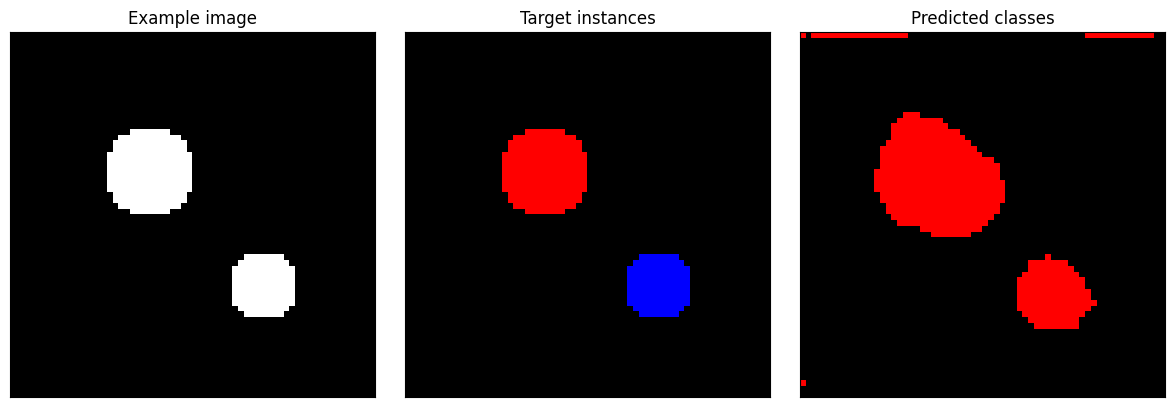

In [7]:
# Check the reloaded network in evaluation mode.
restored.eval()
with torch.inference_mode():
    output = restored(images.to(device))["nuc"]

# Move only the displayed class map to CPU for plotting.
predicted_classes = output.type_map.argmax(dim=1)[0].detach().cpu().numpy()
instance_colors = label2rgb(instances, bg_label=0)
class_colors = label2rgb(predicted_classes, bg_label=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Example image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Target instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()